# Journal 1 - Building the dataset

**Question.** Can we get ~3 000 realistic, correctly labelled tickets for a few dollars, and trust the labels?
**Answer.** Yes: 3 205 tickets for about 3 USD, labels checked by two blind readers and a judge. The limit: labels come from agreement between language models, not from human annotation.

The task: turn a merchant ticket (French or English) into a strict 7-field JSON. Everything below is replayed from the logs in `data/runs/`.

In [1]:
import json, sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "ml/qualifier/src/dataset_build").is_dir())
sys.path[:0] = [str(ROOT), str(ROOT / "ml/qualifier/notebooks")]
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import _viz as viz
from ml.qualifier.src.tracking import build_dataset_manifest
viz.setup()

## 1. The output contract comes first
Generator, scorer and prompt all depend on it, so the closed lists live in one file (`schema.py`).

In [2]:
from ml.qualifier.src.dataset_build import schema
contract = pd.DataFrame([
    ("intent", ", ".join(schema.SUB_INTENTS), "OTHER or UNDEFINED", "never empty"),
    ("sub_intent", "4 per intent (table below)", "OTHER or UNDEFINED", "never empty"),
    ("transaction_id", "TX- followed by 6 digits", "UNDEFINED (malformed or ambiguous)", '"" when absent'),
    ("amount", "decimal with a dot and two decimals", "UNDEFINED", '"" when absent'),
    ("currency", ", ".join(schema.CURRENCIES), "UNDEFINED", '"" when absent'),
    ("urgency", ", ".join(schema.URGENCIES), "UNDEFINED", "never empty"),
    ("sentiment", ", ".join(schema.SENTIMENTS), "UNDEFINED", "never empty"),
], columns=["field", "allowed values", "sentinel", "absent value"]).set_index("field")
display(contract)
pd.DataFrame({i: list(s) for i, s in schema.SUB_INTENTS.items()}).T.rename(columns=lambda c: f"sub-intent {c + 1}")

,allowed values,sentinel,absent value
field,,,
intent,"payment_status, dispute, technical_api, compli...",OTHER or UNDEFINED,never empty
sub_intent,4 per intent (table below),OTHER or UNDEFINED,never empty
transaction_id,TX- followed by 6 digits,UNDEFINED (malformed or ambiguous),""""" when absent"
amount,decimal with a dot and two decimals,UNDEFINED,""""" when absent"
currency,"EUR, USD, GBP, CHF, CAD, SEK, DKK, NOK, PLN",UNDEFINED,""""" when absent"
urgency,"high, medium, low",UNDEFINED,never empty
sentiment,"negative, neutral, positive",UNDEFINED,never empty


,sub-intent 1,sub-intent 2,sub-intent 3,sub-intent 4
payment_status,delayed_credit,missing_payment,status_inquiry,refund_status
dispute,unauthorised_fee,chargeback,duplicate_charge,amount_mismatch
technical_api,webhook_down,api_error,auth_failure,integration_question
compliance,kyc_update,account_hold,document_request,regulatory_question


Four intents, four sub-intents each, plus the sentinels `OTHER` (understood, no class fits) and `UNDEFINED` (cannot tell).

## 2. Three seed prompts, 30 tickets each
Before paying for 3 000 tickets, 30 seeds per prompt version are written from a scenario card (the card fixes the label, the model writes the text) and read by hand.

The writer model receives this prompt (`ml/qualifier/src/dataset_build/config/prompt.toml`). It never sees a label: the situation, urgency and tone are described in the merchant's terms, and the label is the card the brief was built from.

In [3]:
import tomllib
writer_prompt = tomllib.loads((ROOT / "ml/qualifier/src/dataset_build/config/prompt.toml").read_text(encoding="utf-8"))
print("SYSTEM\n" + writer_prompt["system"] + "\n\nUSER TEMPLATE\n" + writer_prompt["user"])

SYSTEM
You write one realistic support ticket sent by a merchant of Keelpay, a B2B payments company. You follow the brief exactly. You write only what the merchant would write: never mention categories, labels, desks, or the brief itself.
Hard rules:
- Strings given between double quotes in the brief must be copied verbatim: same characters, case, spaces and line breaks.
- Never add any other transaction reference (anything like TX-123456), any other amount of money, or any currency name or symbol that the brief does not give. Dates, company names and first names are free.
- If the brief says not to mention a reference or an amount, do not mention one.
- Sign with a first name at most; never invent phone numbers or reference numbers.
- Convey urgency only as the brief asks: add no deadline and no urgency wording (urgent, immediately, as soon as possible, today, 
  and their equivalents in any language) unless the urgency signal calls for it.
Answer with one JSON object and nothing else

In [4]:
def load(path):
    return [json.loads(line) for line in open(path, encoding="utf-8")]

rows = []
for name in ("seeds_v1", "seeds_v2", "seeds"):
    t = load(ROOT / "data/runs" / f"{name}.jsonl")
    rows.append({"prompt version": name, "written": len(t), "pass checks": sum(x["status"] == "ok" for x in t),
                 "cost (USD)": round(sum(x["cost_usd"] for x in t), 3)})
pd.DataFrame(rows).set_index("prompt version")

,written,pass checks,cost (USD)
prompt version,,,
seeds_v1,30,29,0.018
seeds_v2,30,29,0.020
seeds,30,28,0.022


28-29 of 30 pass the structural checks at ~0.02 USD per version. The checks say nothing about realism: that was a human read of the last 30 (`data/seeds/seeds_review.md`), judged realistic.

## 3. Gate 2: the full review chain on 100 cards, three times
Chain per ticket: deterministic checks, then two blind "voters", then a stronger judge only if they disagree with each other or with the card. A failing ticket is quarantined, never repaired.

,tickets,failed checks,judge called,accepted,cost / ticket (USD)
run,,,,,
run 1,100,7,59,61,0.0012
run 2,100,2,52,70,0.0008
final,100,3,43,75,0.0007


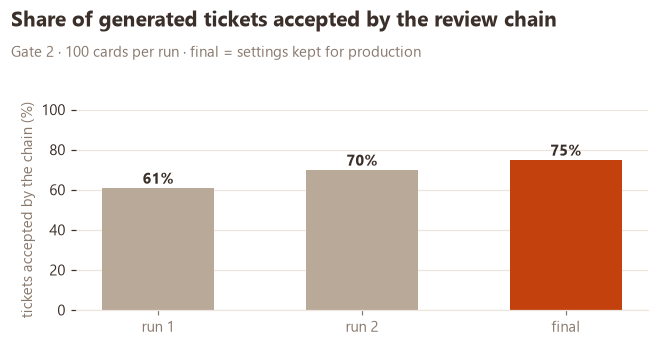

In [5]:
def gate(dirpath, tag):
    t, r = load(dirpath / "gate2_tickets.jsonl"), load(dirpath / "gate2_reviews.jsonl")
    cost = sum(x["cost_usd"] for x in t) + sum(x["cost_usd"] for x in r)
    return {"run": tag, "tickets": len(t), "failed checks": sum(x["status"] != "ok" for x in t),
            "judge called": sum(x["judge_verdict"] not in (None, "") for x in r),
            "accepted": sum(x["final"] == "accepted" for x in r), "cost / ticket (USD)": round(cost / len(t), 4)}

runs = pd.DataFrame([gate(ROOT / "data/runs/_gate2_run1", "run 1"), gate(ROOT / "data/runs/_gate2_run2", "run 2"),
                     gate(ROOT / "data/runs", "final")]).set_index("run")
rate = runs["accepted"] / runs["tickets"]
display(runs)

fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.bar(runs.index, rate * 100, color=[viz.NEUTRAL, viz.NEUTRAL, viz.ACCENT], width=0.55)
for b, r in zip(bars, rate):
    ax.text(b.get_x() + b.get_width() / 2, r * 100 + 2, f"{r:.0%}", ha="center", fontweight="bold")
ax.set_ylim(0, 100); ax.set_ylabel("tickets accepted by the chain (%)"); ax.grid(axis="x", visible=False)
viz.headline(fig, "Share of generated tickets accepted by the review chain", "Gate 2 · 100 cards per run · final = settings kept for production")
viz.save(fig, "01_chain_pass_rate")
plt.show()

Pass rate 61 -> 70 -> 75 %, at a falling cost (0.0012 -> 0.0007 USD per ticket, under half the 0.0018 estimated). A quarter still fails: next, why.

## 4. Where do the rejections come from?
A ticket goes to the judge when a voter's reading differs from the card. Counting the fields that differ, per voter (final Gate 2 run):

In [6]:
reviews = load(ROOT / "data/runs/gate2_reviews.jsonl")
diff = pd.DataFrame([{"voter": v["role"], "field": f} for r in reviews for v in r["votes"] for f in v["differing_fields"]])
table = diff.groupby(["field", "voter"]).size().unstack(fill_value=0)
table.loc[table.sum(axis=1).sort_values(ascending=False).index]

voter,voter_a,voter_b
field,,
urgency,21,10
sub_intent,14,13
intent,13,10
sentiment,10,4
currency,2,2
amount,1,1
transaction_id,2,0


Doubt sits on the subjective fields (urgency, sentiment) and on neighbouring sub-intents. The reference fields (`transaction_id`, `amount`, `currency`) almost never differ. So the labels are solid where extraction matters and softer where humans would also disagree.

## 5. The production run, split by split
Targets: train 2 000, val 300, test_natural 500, test_traps ~391. A split is closed at 90 % of its target at the latest. Tests are written by a different model than train/val, so the model cannot be scored on its own writer's style.

,target,attempted,accepted,quarantined,cost (USD)
split,,,,,
train,2000,2657,1922,735,1.85
val,300,450,293,157,0.24
test_natural,500,950,610,340,0.56
test_traps,391,645,380,265,0.42


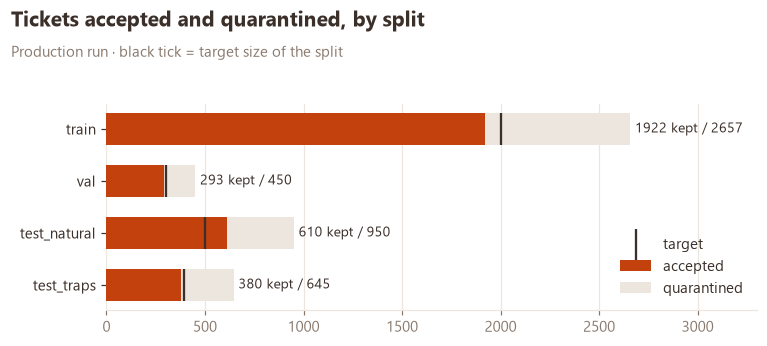

total cost: 3.07 USD


In [7]:
targets = {"train": 2000, "val": 300, "test_natural": 500, "test_traps": 391}
rows = []
for split, target in targets.items():
    t = load(ROOT / f"data/runs/prod_{split}_tickets.jsonl"); r = load(ROOT / f"data/runs/prod_{split}_reviews.jsonl")
    verdict = {x["card_id"]: x["final"] for x in r}
    ok = sum(verdict.get(x["card_id"]) == "accepted" and x["status"] == "ok" for x in t)
    rows.append({"split": split, "target": target, "attempted": len(t), "accepted": ok, "quarantined": len(t) - ok,
                 "cost (USD)": sum(x["cost_usd"] for x in t) + sum(x["cost_usd"] for x in r)})
prod = pd.DataFrame(rows).set_index("split")
display(prod.round({"cost (USD)": 2}))

fig, ax = plt.subplots(figsize=(7, 3.2))
ys = np.arange(len(prod))
ax.barh(ys, prod["accepted"], color=viz.ACCENT, height=0.6, label="accepted")
ax.barh(ys, prod["quarantined"], left=prod["accepted"], color=viz.GRID, height=0.6, label="quarantined")
ax.scatter(prod["target"], ys, marker="|", s=420, color=viz.INK, zorder=3, label="target")
for y, (a, q) in enumerate(zip(prod["accepted"], prod["attempted"])):
    ax.text(q + 25, y, f"{a} kept / {q}", va="center", fontsize=9, color=viz.INK)
ax.set_yticks(ys, prod.index); ax.invert_yaxis(); ax.set_xlim(0, 3300); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
viz.headline(fig, "Tickets accepted and quarantined, by split", "Production run · black tick = target size of the split")
viz.save(fig, "01_split_funnel")
plt.show()
print(f"total cost: {prod['cost (USD)'].sum():.2f} USD")

Acceptance is 72 % (train), 65 (val), 64 (test_natural), 59 (test_traps): lower on tests because another model writes them and the traps are built to be hard. Every split clears its 90 % floor.

Two flaws recorded: `test_natural` ended at 610 instead of 500 (an interrupted run had lost some verdicts, so the stop condition did not fire; kept, it gives more tickets for the headline numbers), and the logs add up to 3.07 USD against 3.44 USD on the run's own counter (gap not reconciled, still far below the 8 USD limit).

## 6. What the exported dataset teaches and measures

In [8]:
splits = {s: pd.read_csv(ROOT / f"data/dataset/{s}.csv", keep_default_na=False) for s in targets}
for df in splits.values():
    df["intent"] = df["target"].map(lambda t: json.loads(t)["intent"])
share = pd.DataFrame({s: df["intent"].value_counts(normalize=True) for s, df in splits.items()})
display((share * 100).round(0).astype(int).astype(str) + " %")
traps = pd.Series([t for t in "|".join(splits["test_traps"]["traps"]).split("|") if t]).value_counts()
print(f"test_traps: {len(traps)} trap types, {int((traps < 20).sum())} below 20 tickets (smallest: {traps.idxmin()} = {traps.min()})")

,train,val,test_natural,test_traps
intent,,,,
OTHER,8 %,7 %,6 %,1 %
UNDEFINED,11 %,10 %,10 %,7 %
compliance,21 %,20 %,19 %,16 %
dispute,20 %,22 %,23 %,38 %
payment_status,18 %,19 %,19 %,26 %
technical_api,22 %,22 %,24 %,13 %


test_traps: 23 trap types, 9 below 20 tickets (smallest: id_split_lines = 6)


### Two tickets and their labels
One French and one English ticket from `train`, with the JSON the model must return.

In [9]:
for lang in ("fr", "en"):
    row = splits["train"][splits["train"]["language"] == lang].iloc[0]
    print(f"--- {lang} ticket ({row['channel']})\n{row['ticket']}\n\n--- expected JSON\n{json.dumps(json.loads(row['target']), indent=2, ensure_ascii=False)}\n")

--- fr ticket (forwarded_thread)
Subject: Écart de montant sur un paiement reçu

Bonjour,

Je transfère ci-dessous notre échange : le montant reçu ne correspond toujours pas à ce qui était attendu, et si cela ne se règle pas rapidement de votre côté, nous irons voir ailleurs.

> De : Keelpay
> À : Élodie
> Objet : RE: Écart de montant sur un paiement reçu
>
> Bonjour,
>
> Merci pour votre message. Nous revenons vers vous dès que possible.
>
> Cordialement,
> Le support Keelpay

Élodie
Fondatrice, Marché en ligne
Ma Place du Marché

--- expected JSON
{
  "intent": "dispute",
  "sub_intent": "amount_mismatch",
  "transaction_id": "",
  "amount": "",
  "currency": "",
  "urgency": "medium",
  "sentiment": "negative"
}

--- en ticket (forwarded_thread)
Subject: Status of refund for TX-520024

Hi, I'm forwarding the exchange below and would like to know where things stand with the refund for TX-520024.

---------- Forwarded message ----------
From: Mira Halvorsen <mira@northlinelogistics.ex

### Intent mix across splits
This chart shows why `test_traps` is diagnostic rather than a representative overall score.


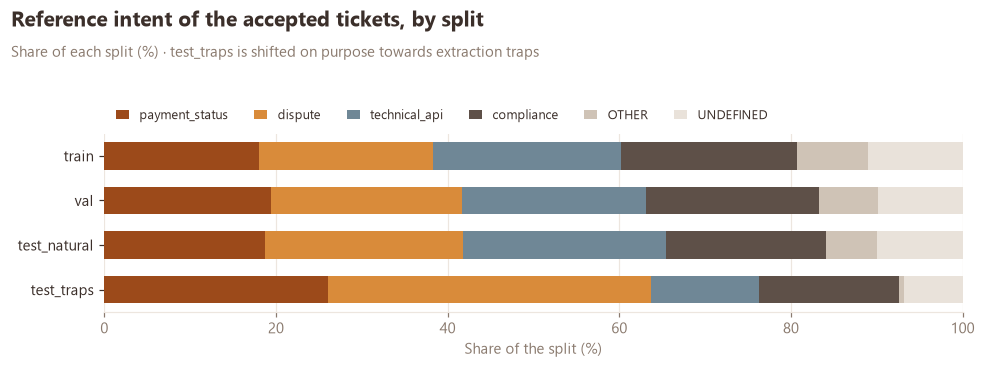

In [10]:
mix = pd.DataFrame({s: df['intent'].value_counts(normalize=True) for s, df in splits.items()}).fillna(0).T * 100
mix = mix[[k for k in viz.INTENT_COLORS if k in mix.columns]]
fig, ax = plt.subplots(figsize=(9, 3.4))
left = np.zeros(len(mix))
for intent in mix.columns:
    ax.barh(mix.index, mix[intent], left=left, color=viz.INTENT_COLORS[intent], height=0.62, label=intent)
    left += mix[intent].to_numpy()
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel('Share of the split (%)'); ax.grid(axis='y', visible=False)
ax.legend(ncol=6, loc='lower left', bbox_to_anchor=(0, 1.0), fontsize=8.5, handlelength=1)
viz.headline(fig, 'Reference intent of the accepted tickets, by split', 'Share of each split (%) · test_traps is shifted on purpose towards extraction traps')
viz.save(fig, '01_intent_distribution')
plt.show()

In [11]:
print(f"test_traps: {len(traps)} trap families, {int((traps < 20).sum())} with fewer than 20 tickets (per-family rates there are anecdotal)")

test_traps: 23 trap families, 9 with fewer than 20 tickets (per-family rates there are anecdotal)


Train, val and test_natural share the same mix (each intent ~1/5, `OTHER` 6-8 %, `UNDEFINED` 10-11 %). `test_traps` is deliberately different (disputes 38 %, almost no `OTHER`): it cannot give a global score, only a diagnosis per trap type, and 9 of 23 types have fewer than 20 tickets, so their per-family rates are read as anecdotal.

**Final dataset: train 1 922 / val 293 / test_natural 610 / test_traps 380**, each with its quarantine. Next: how to score a system, and what the simple baselines achieve.

## Data version fingerprint

The manifest records each committed split hash, row count, and column schema. Vertex object generations are added when a cloud run manifest is recovered.


In [12]:
dataset_manifest = build_dataset_manifest(ROOT / "data/dataset")
pd.DataFrame.from_dict(dataset_manifest["splits"], orient="index").rename_axis("split")

,sha256,rows,columns
split,,,
test_natural.csv,a71b7b14f5c4b1d96d576e51f15c5459e55f5d74c9ef36...,610,"[card_id, ticket, target, traps, language, cha..."
test_natural_quarantine.csv,b393751c2f369fb7c9ea8cc0e57ceb599e5ff5800c73b7...,340,"[reason, card_id, ticket, target, traps, langu..."
test_traps.csv,3bb153bc3bde7053634a2b174d6dcd9f5379a329cab6cc...,380,"[card_id, ticket, target, traps, language, cha..."
test_traps_quarantine.csv,e43f38ef6a8886d9ec1426056e15349fee9b31236ad21f...,265,"[reason, card_id, ticket, target, traps, langu..."
train.csv,ad758b61b19ef6c41a4459a1013b1e0ed6dfdc753e0131...,1922,"[card_id, ticket, target, traps, language, cha..."
train_quarantine.csv,f186219e22176a9541236307df1421761b0103697e9fe0...,735,"[reason, card_id, ticket, target, traps, langu..."
val.csv,e33a1445911555300c43bc0cc3381033e6f6bd8f237666...,293,"[card_id, ticket, target, traps, language, cha..."
val_quarantine.csv,dee2b346b5ce540a0ff86d6dabc1467e07bc621f98b8d3...,157,"[reason, card_id, ticket, target, traps, langu..."
